# İç Denetimde Veri Analizi — İleri Konular II
## Örnekleme, Çok Değişkenli Aykırılık ve Zaman Serisi Analizi

**Dr. Suat ATAN**

Bu notebook'un amacı Python öğretmekten çok, denetçinin şu üç soruyu daha iyi sormasını sağlamaktır:

1. **Her kayda bakamıyorsam hangilerine bakmalıyım?**
2. **Tek tek normal görünen değişkenler birlikte ele alındığında olağandışı bir kayıt oluşturuyor mu?**
3. **Bir işlem tek başına normal görünse bile zaman içindeki davranış değişmiş mi?**

Bu üç soru bizi sırasıyla **örnekleme**, **Mahalanobis uzaklığı** ve **zaman serisi anomalileri** konularına götürecek.

> Bu notebook'ta temel ilke şudur: Analitik bir test “usulsüzlük bulmaz”.  
> Analitik test, **denetçinin dikkatini nereye yönelteceğini** söyler.

## 0. Küçük bir düşünce deneyi

Elinizde 100.000 ödeme kaydı olduğunu düşünün.

Hepsini tek tek incelemek mümkün değildir. Bu durumda ilk refleks genellikle şöyledir:

> “Rastgele 100 kayıt seçelim.”

Bu kötü bir fikir değildir. Hatta bazı denetim amaçları için tam olarak doğru yaklaşımdır.  
Ama her denetim sorusu **aynı örnekleme mantığını** gerektirmez.

Örneğin:

- “Kurum genelindeki hata oranını tahmin etmek” istiyorsak **rastgele örnekleme** mantıklıdır.
- “Her bölgeden yeterli kayıt görmek” istiyorsak **tabakalı örnekleme** daha iyidir.
- “Parasal etkisi yüksek işlemlere daha fazla şans vermek” istiyorsak **PPS / tutarla orantılı örnekleme** daha anlamlıdır.

Denetimde analitik düşünmenin önemli bir kısmı, doğru algoritmayı seçmekten önce **doğru soruyu seçmektir**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

n = 1500
dates = pd.date_range("2025-01-01", "2026-06-30", freq="D")

df = pd.DataFrame({
    "islem_id": [f"TRX-{i:05d}" for i in range(1, n + 1)],
    "tarih": np.random.choice(dates, size=n),
    "birim": np.random.choice(
        ["Merkez", "Kuzey", "Güney", "Doğu"],
        size=n,
        p=[0.35, 0.20, 0.25, 0.20]
    ),
    "tedarikci": np.random.choice(
        [f"Tedarikçi-{i:02d}" for i in range(1, 41)],
        size=n
    ),
})

# Sağ kuyruğu olan parasal büyüklük: denetim verilerinde oldukça tipik.
df["tutar"] = np.random.lognormal(mean=11.0, sigma=0.75, size=n).round(2)

# Onay süresi çoğunlukla 5–30 gün civarında.
df["onay_suresi_gun"] = np.clip(
    np.random.normal(loc=16, scale=5, size=n),
    1, None
).round(1)

# Birkaç yapay anomali ekleyelim.
anomali_idx = np.random.choice(df.index, size=12, replace=False)
df.loc[anomali_idx[:6], "tutar"] *= np.random.uniform(5, 9, size=6)
df.loc[anomali_idx[6:], "onay_suresi_gun"] = np.random.uniform(0.5, 2.0, size=6)

# Birkaç kayıtta hem tutar yüksek hem onay süresi olağan dışı kısa olsun.
kombine_idx = np.random.choice(df.index.difference(anomali_idx), size=5, replace=False)
df.loc[kombine_idx, "tutar"] *= np.random.uniform(4, 7, size=5)
df.loc[kombine_idx, "onay_suresi_gun"] = np.random.uniform(0.5, 1.5, size=5)

df = df.sort_values("tarih").reset_index(drop=True)
df.head()

,islem_id,tarih,birim,tedarikci,tutar,onay_suresi_gun
0,TRX-00846,2025-01-01,Güney,Tedarikçi-05,39324.03,14.1
1,TRX-00475,2025-01-01,Güney,Tedarikçi-17,55760.45,9.3
2,TRX-00558,2025-01-01,Merkez,Tedarikçi-05,99133.82,17.7
3,TRX-01485,2025-01-01,Güney,Tedarikçi-16,42113.32,10.3
4,TRX-00734,2025-01-01,Güney,Tedarikçi-08,32833.34,21.5


# 1. Örnekleme: “Hangi kayıtlara bakacağız?”

Örnekleme bazen “verinin küçük bir kısmını almak” gibi anlatılır. Bu eksik bir tanımdır.

Asıl mesele şudur:

> **Seçtiğimiz küçük grup, hangi soruya cevap verecek?**

Bir hastanede ateşi olan hastaları araştırıyorsanız, sadece hastanenin kapısından rastgele geçen insanlara bakmak başka bir şeydir; yoğun bakım hastalarını özellikle seçmek başka bir şeydir.

Denetimde de aynı ayrım vardır.

### Basit rastgele örnekleme

Her kaydın seçilme olasılığı aynıdır.

Bu yöntem özellikle:

- genel hata oranı,
- prosedüre uyum oranı,
- kayıt kalitesinin genel düzeyi

gibi konularda kullanışlıdır.

Avantajı sadeliğidir.  
Dezavantajı ise küçük ama önemli grupları örnek dışında bırakabilmesidir.

In [2]:
# Basit rastgele örnekleme
ornek_rastgele = df.sample(n=50, random_state=42)

ornek_rastgele[["islem_id", "birim", "tutar", "onay_suresi_gun"]].head(10)

,islem_id,birim,tutar,onay_suresi_gun
1116,TRX-00405,Güney,240124.16,11.0
1368,TRX-01072,Kuzey,222022.11,11.8
422,TRX-00414,Kuzey,45130.67,15.1
413,TRX-01106,Merkez,74928.63,15.5
451,TRX-01082,Doğu,85945.47,26.5
861,TRX-00649,Merkez,37778.43,12.5
1063,TRX-01316,Merkez,73609.78,11.2
741,TRX-00359,Güney,39632.18,18.4
1272,TRX-01288,Merkez,26433.15,13.3
259,TRX-00927,Güney,72326.37,6.5


## 1.1 Tabakalı örnekleme

Dört birimimiz olduğunu düşünelim. Kayıtların %35'i Merkez'den geliyor, geri kalanı diğer birimlere dağılıyor.

Tamamen rastgele 20 kayıt seçersek küçük bir birimden hiç kayıt gelmeme ihtimali vardır.

**Tabakalı örnekleme** önce veriyi anlamlı gruplara ayırır, sonra her grubun içinden örnek seçer.

Bu gruplara *tabaka* denir.

Denetimde tabaka olarak şunlar kullanılabilir:

- bölge,
- işlem türü,
- ihale türü,
- destek programı,
- risk sınıfı,
- parasal büyüklük sınıfı.

Burada önemli nokta şudur:

> Tabakalama bir istatistik tekniği olduğu kadar bir **denetim tasarımı** tekniğidir.

Çünkü “hangi grupların ayrı ayrı temsil edilmesi gerekir?” sorusu tamamen denetim amacına bağlıdır.

In [3]:
# Her birimden 12 kayıt seçelim.
ornek_tabakali = (
    df.groupby("birim", group_keys=False)
      .apply(lambda x: x.sample(n=min(12, len(x)), random_state=42))
      .reset_index(drop=True)
)

ornek_tabakali["birim"].value_counts()

/tmp/ipykernel_406/1457409669.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(12, len(x)), random_state=42))


birim
Doğu      12
Güney     12
Kuzey     12
Merkez    12
Name: count, dtype: int64

## 1.2 PPS — Probability Proportional to Size

Şimdi farklı bir soru soralım.

100 TL'lik bir ödeme ile 10 milyon TL'lik bir ödemenin seçilme olasılığı gerçekten aynı mı olmalı?

Her zaman değil.

**PPS (Probability Proportional to Size)** yaklaşımında kaydın seçilme olasılığı büyüklüğüyle orantılıdır.  
Denetimde “size” çoğu zaman **tutar**dır.

Dolayısıyla büyük işlemlerin örneğe girme ihtimali artar.

Bu yöntem özellikle parasal hata riskinin önemli olduğu durumlarda kullanışlıdır.

Ama dikkat:

> PPS, “büyük işlem daha şüphelidir” demez.  
> “Büyük işlemin olası parasal etkisi daha yüksektir” der.

Bu iki cümle birbirinden çok farklıdır.

In [4]:
# Pandas sample() fonksiyonu ağırlıklı örneklemeye izin verir.
ornek_pps = df.sample(
    n=50,
    weights="tutar",
    random_state=42
)

karsilastirma = pd.DataFrame({
    "Tum veri": df["tutar"].describe()[["mean", "50%", "max"]],
    "Rastgele örnek": ornek_rastgele["tutar"].describe()[["mean", "50%", "max"]],
    "PPS örneği": ornek_pps["tutar"].describe()[["mean", "50%", "max"]],
})

karsilastirma

,Tum veri,Rastgele örnek,PPS örneği
mean,8.107556e+04,75148.2728,161180.378752
50%,5.965840e+04,64139.1950,110976.095000
max,1.007570e+06,240124.1600,930312.990000


### Tabloyu nasıl okumalıyız?

Bu tablo PPS'nin ne yaptığını çok güzel gösteriyor.

**Tüm veri** sütunu, 1.500 işlemin genel yapısını özetliyor. Ortalama işlem tutarı yaklaşık **81 bin TL**, medyan ise yaklaşık **60 bin TL**. Ortalamanın medyandan yüksek olması normaldir; çünkü işlem tutarları sağa çarpık bir dağılıma sahiptir: az sayıdaki büyük işlem ortalamayı yukarı çeker.

**Rastgele örnek** bu genel yapıya oldukça yakın kalmıştır. Ortalama yaklaşık **75 bin TL**, medyan yaklaşık **64 bin TL**. Bunun nedeni basit rastgele örneklemede her işlemin seçilme şansının aynı olmasıdır. Bu yüzden yeterince büyük bir örnek, genel veri setinin dağılımını kabaca taklit etme eğilimindedir.

**PPS örneğinde ise ortalama yaklaşık 161 bin TL'ye, medyan yaklaşık 111 bin TL'ye çıkıyor.** Bu bir hata değildir; PPS'nin özellikle yapmak istediği şey budur.

PPS'de seçim olasılığı işlem tutarıyla orantılıdır. Örneğin:

- 10.000 TL'lik bir işlemin ağırlığı yaklaşık 10.000,
- 100.000 TL'lik işlemin ağırlığı yaklaşık 100.000,
- 1.000.000 TL'lik işlemin ağırlığı yaklaşık 1.000.000'dur.

Dolayısıyla 1 milyon TL'lik kayıt, 10 bin TL'lik kayda göre örneğe girme konusunda çok daha yüksek şansa sahiptir. Sonuç olarak örneğin içinde **yüksek tutarlı işlemler yoğunlaşır** ve örnek ortalaması doğal olarak tüm veri ortalamasından yükselir.

Tablodaki **maksimum** değer de bunu gösteriyor. Rastgele örnekte görülen en yüksek tutar yaklaşık **240 bin TL** iken PPS örneğinde yaklaşık **930 bin TL**'lik bir işlem örneğe girmiştir. PPS büyük parasal işlemleri özellikle görünür hale getirmektedir.

> **Denetim yorumu:** PPS'nin amacı anakütlenin “tipik işlemini” temsil etmek değildir.  
> Amacı, **parasal etkisi yüksek kayıtların denetim örneğine girme olasılığını artırmaktır.**

Bu nedenle hangi örneklemenin kullanılacağı denetim sorusuna bağlıdır:

**“İşlemlerin genelinde hata oranı nedir?”** sorusunda rastgele örnek daha uygundur.  
**“Mali etkisi yüksek yanlışlıkları yakalamak istiyorum.”** sorusunda ise PPS daha anlamlı olabilir.

Bir başka önemli nokta da şudur: **yüksek tutar = yüksek usulsüzlük riski değildir.** PPS, usulsüzlük olasılığını değil, olası bir hatanın **parasal etkisini** örnekleme tasarımına dahil eder.

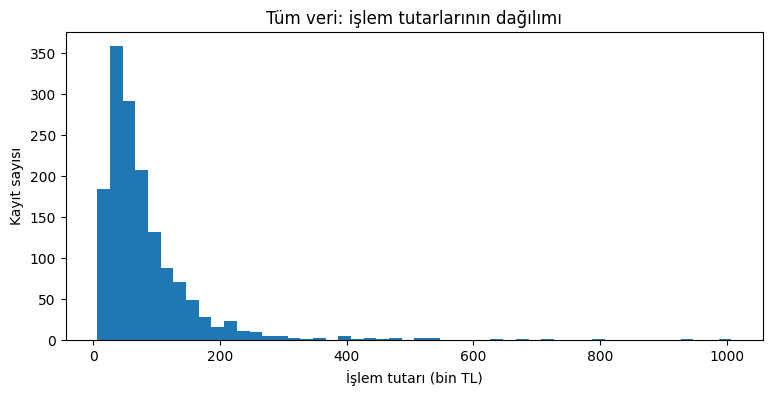

In [5]:
plt.figure(figsize=(9, 4))
plt.hist(df["tutar"] / 1000, bins=50)
plt.xlabel("İşlem tutarı (bin TL)")
plt.ylabel("Kayıt sayısı")
plt.title("Tüm veri: işlem tutarlarının dağılımı")
plt.show()

### Denetçi gözüyle sonuç

Burada tek bir “en iyi örnekleme yöntemi” yoktur.

- **Rastgele örnekleme:** Genel görünümü tahmin etmeye çalışır.
- **Tabakalı örnekleme:** Önemli grupların görünür kalmasını sağlar.
- **PPS:** Parasal büyüklüğü örnekleme tasarımının içine sokar.

İyi bir denetçi önce `sample()` fonksiyonunu değil, **denetim iddiasını** düşünür.

### Mini alıştırma

Aşağıdaki üç durumda hangi yaklaşımı tercih ederdiniz?

1. Dört bölgenin de satın alma prosedürüne uyumunu karşılaştırmak.
2. Kurum genelindeki belge eksikliği oranını tahmin etmek.
3. Yanlış ödeme varsa parasal etkisi yüksek vakalara öncelik vermek.

Cevapları koddan önce düşünün.

# 2. Tek değişkenli aykırı değer neden bazen yetmez?

Bir işlemin sadece tutarına baktığımızı düşünelim.

200.000 TL'lik işlem normal olabilir.

Sadece onay süresine baktığımızda 4 günlük onay da normal olabilir.

Fakat şu kombinasyon ilginç olabilir:

> **Çok yüksek tutar + olağan dışı kısa onay süresi**

Tek tek bakıldığında iki değer de sınırların içinde olabilir.  
Fakat **birlikte** değerlendirildiğinde sıra dışı olabilirler.

Bu nokta bizi çok değişkenli aykırılık kavramına getirir.

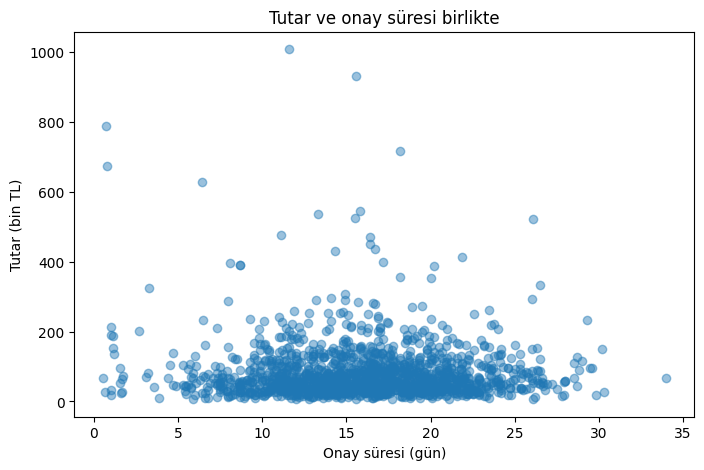

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df["onay_suresi_gun"], df["tutar"] / 1000, alpha=0.45)
plt.xlabel("Onay süresi (gün)")
plt.ylabel("Tutar (bin TL)")
plt.title("Tutar ve onay süresi birlikte")
plt.show()

# 3. Mahalanobis Uzaklığı

Öklid uzaklığını hepimiz sezgisel olarak biliriz.

Bir nokta merkezden ne kadar uzakta?

Fakat finansal ve operasyonel verilerde değişkenlerin:

- ölçekleri farklı olabilir,
- birbirleriyle ilişkili olabilir.

Örneğin işlem tutarı yüz binlerle ölçülürken onay süresi günlerle ölçülür.  
Bu iki ekseni olduğu gibi kullanmak doğru değildir.

Mahalanobis uzaklığı iki şeyi dikkate alır:

1. Her değişkenin doğal yayılımını,
2. Değişkenlerin birbirleriyle olan kovaryansını.

Basitleştirilmiş olarak:

\[
D^2 = (x-\mu)^T S^{-1}(x-\mu)
\]

Burada:

- \(x\): incelediğimiz kayıt,
- \(\mu\): değişkenlerin ortalama vektörü,
- \(S\): kovaryans matrisi,
- \(D\): Mahalanobis uzaklığıdır.

Formülü ezberlemek gerekmiyor.

Sezgisel karşılığı şudur:

> **“Bu kayıt, verinin doğal şekline göre ne kadar uzakta?”**

Mahalanobis uzaklığı bir kaydın “büyük” olmasını değil, **alışılmadık bir kombinasyon** oluşturmasını yakalamaya çalışır.

In [7]:
from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2

X = df[["tutar", "onay_suresi_gun"]].astype(float)

ortalama = X.mean().values
kovaryans = np.cov(X.values, rowvar=False)
ters_kovaryans = np.linalg.inv(kovaryans)

df["mahalanobis"] = X.apply(
    lambda row: mahalanobis(row.values, ortalama, ters_kovaryans),
    axis=1
)

df[["islem_id", "tutar", "onay_suresi_gun", "mahalanobis"]].sort_values(
    "mahalanobis", ascending=False
).head(10)

,islem_id,tutar,onay_suresi_gun,mahalanobis
513,TRX-00725,1.007570e+06,11.600000,11.550773
669,TRX-00672,9.303130e+05,15.600000,10.588675
679,TRX-00139,7.874021e+05,0.752569,9.172866
1001,TRX-01225,7.154674e+05,18.200000,7.941629
324,TRX-00684,6.733807e+05,0.784856,7.837492
1373,TRX-00452,6.271050e+05,6.400000,6.983322
491,TRX-00446,5.208275e+05,26.100000,5.901552
812,TRX-00370,5.445791e+05,15.800000,5.779375
184,TRX-00315,5.369684e+05,13.300000,5.687810
767,TRX-01263,5.256288e+05,15.500000,5.541275


## 3.1 “Kaçtan sonrası anormal?”

Burada sihirli ve evrensel bir eşik yoktur.

Fakat teorik bir başlangıç noktası olarak Mahalanobis uzaklığının karesi, belirli varsayımlar altında **ki-kare dağılımıyla** ilişkilendirilebilir.

İki değişken kullandığımız için serbestlik derecesi 2'dir.

Örneğin %99'luk teorik eşiği hesaplayabiliriz.

Bu eşiği şöyle yorumlamak daha sağlıklıdır:

> “Bu sınırın üzerindeki kayıtlar otomatik olarak hatalıdır” değil,  
> **“Bu kayıtlar inceleme kuyruğunda yukarı taşınabilir.”**

Denetimde model sonucu karar değildir; **kanıt toplama sürecinin başlangıcıdır**.

In [8]:
esik_kare = chi2.ppf(0.99, df=2)
esik = np.sqrt(esik_kare)

df["mahalanobis_flag"] = df["mahalanobis"] > esik

print("Mahalanobis eşiği:", round(esik, 2))
print("İşaretlenen kayıt sayısı:", int(df["mahalanobis_flag"].sum()))

df.loc[df["mahalanobis_flag"],
       ["islem_id", "birim", "tutar", "onay_suresi_gun", "mahalanobis"]].sort_values(
    "mahalanobis", ascending=False
).head(15)

Mahalanobis eşiği: 3.03
İşaretlenen kayıt sayısı: 32


,islem_id,birim,tutar,onay_suresi_gun,mahalanobis
513,TRX-00725,Güney,1.007570e+06,11.600000,11.550773
669,TRX-00672,Kuzey,9.303130e+05,15.600000,10.588675
679,TRX-00139,Güney,7.874021e+05,0.752569,9.172866
1001,TRX-01225,Kuzey,7.154674e+05,18.200000,7.941629
324,TRX-00684,Merkez,6.733807e+05,0.784856,7.837492
1373,TRX-00452,Güney,6.271050e+05,6.400000,6.983322
491,TRX-00446,Doğu,5.208275e+05,26.100000,5.901552
812,TRX-00370,Merkez,5.445791e+05,15.800000,5.779375
184,TRX-00315,Güney,5.369684e+05,13.300000,5.687810
767,TRX-01263,Kuzey,5.256288e+05,15.500000,5.541275


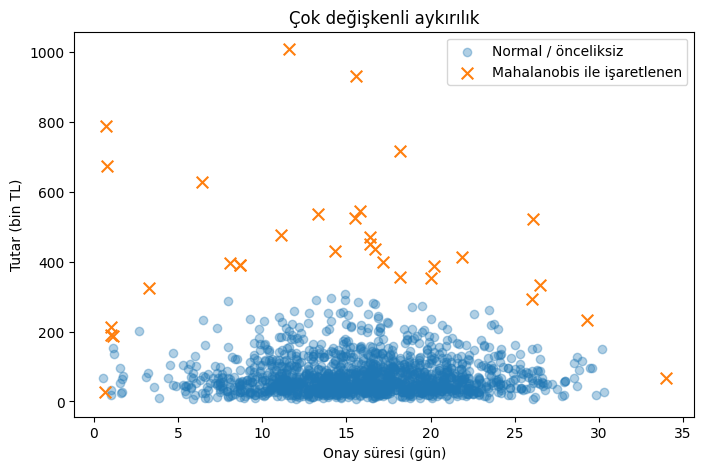

In [9]:
plt.figure(figsize=(8, 5))

normal = df[~df["mahalanobis_flag"]]
supheli = df[df["mahalanobis_flag"]]

plt.scatter(
    normal["onay_suresi_gun"],
    normal["tutar"] / 1000,
    alpha=0.35,
    label="Normal / önceliksiz"
)

plt.scatter(
    supheli["onay_suresi_gun"],
    supheli["tutar"] / 1000,
    marker="x",
    s=70,
    label="Mahalanobis ile işaretlenen"
)

plt.xlabel("Onay süresi (gün)")
plt.ylabel("Tutar (bin TL)")
plt.title("Çok değişkenli aykırılık")
plt.legend()
plt.show()

### Denetçi için önemli uyarı

Mahalanobis uzaklığı **neden** bir kaydın sıra dışı olduğunu tek başına açıklamaz.

Örneğin model şu kaydı yukarı taşıyabilir:

- Tutar: yüksek
- Onay süresi: çok kısa

Ama denetçinin asıl işi bundan sonra başlar:

- Acil durum prosedürü mü vardı?
- İşlem önceden çerçeve sözleşmeyle mi yapılmıştı?
- Yetkili onayı mevcut mu?
- Benzer büyüklükteki işlemler normalde kaç günde tamamlanıyor?
- Aynı tedarikçiyle benzer örüntü tekrar ediyor mu?

İyi analitik, denetçinin yerini almaz.  
**İyi analitik, denetçinin merceğini keskinleştirir.**

# 4. Zaman serisi: Tek bir kayıt değil, davranış değişikliği

Şimdi düşünce biçimimizi değiştirelim.

Bir ayda 50 işlem yapılması tek başına olağan olabilir.

Ama aylardır 15–20 işlem yapılırken bir anda 50'ye çıkılması önemli olabilir.

Zaman serisi analizinin denetime kattığı temel fikir şudur:

> Bir değerin “normal” olup olmadığını anlamak için yalnızca büyüklüğüne değil,  
> **geçmiş davranışına göre konumuna** da bakabiliriz.

Bu özellikle şu sorular için değerlidir:

- Harcamalarda ani artış oldu mu?
- Yıl sonuna doğru sıra dışı ödeme yoğunluğu oluştu mu?
- Belirli bir tarihten sonra süreç süresi değişti mi?
- Yeni bir uygulama sonrasında hata oranı arttı mı?

In [10]:
aylik = (
    df.set_index("tarih")
      .resample("MS")
      .agg(
          toplam_tutar=("tutar", "sum"),
          islem_sayisi=("islem_id", "count"),
          ort_onay_suresi=("onay_suresi_gun", "mean")
      )
      .reset_index()
)

# Eğitim için belirgin bir zaman kırılması oluşturalım:
# 2026 Mart sonrasında toplam tutarın bazı aylarda yükseldiğini varsayalım.
mask = aylik["tarih"] >= "2026-03-01"
aylik.loc[mask, "toplam_tutar"] *= np.array(
    [1.7, 1.9, 1.6, 2.0][:mask.sum()]
)

aylik.tail(8)

,tarih,toplam_tutar,islem_sayisi,ort_onay_suresi
10,2025-11-01,6.473222e+06,80,16.691250
11,2025-12-01,6.283685e+06,87,15.581609
12,2026-01-01,7.929879e+06,89,16.002247
13,2026-02-01,5.191076e+06,73,16.434247
14,2026-03-01,8.351560e+06,68,16.621322
15,2026-04-01,1.121176e+07,79,16.131410
16,2026-05-01,1.300791e+07,90,15.832902
17,2026-06-01,1.198129e+07,70,15.982857


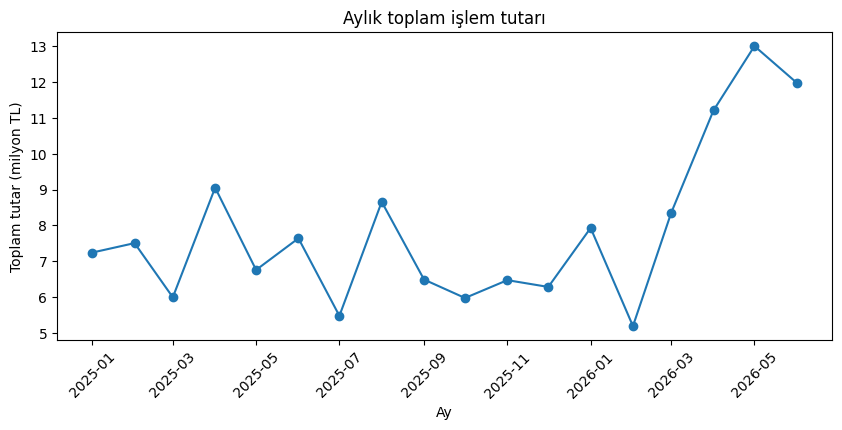

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(aylik["tarih"], aylik["toplam_tutar"] / 1_000_000, marker="o")
plt.xlabel("Ay")
plt.ylabel("Toplam tutar (milyon TL)")
plt.title("Aylık toplam işlem tutarı")
plt.xticks(rotation=45)
plt.show()

## 4.1 Hareketli ortalama mı, hareketli medyan mı?

Zaman serilerinde “yakın geçmişte normal neydi?” sorusunu sormak için hareketli pencereler kullanılır.

Örneğin son 5 ayın ortalamasını hesaplayabiliriz.

Ancak denetim verilerinde tek bir dev işlem ortalamayı kolayca yukarı çekebilir.

Bu nedenle **hareketli medyan** çoğu zaman daha dayanıklıdır.

Örnek:

`10, 11, 12, 12, 100`

Ortalama = 29  
Medyan = 12

100'lük tek bir uç değer ortalamayı ciddi biçimde bozarken medyan tipik davranışı korur.

Bu yüzden denetim analitiğinde “robust / dayanıklı” istatistikler sık sık faydalıdır.

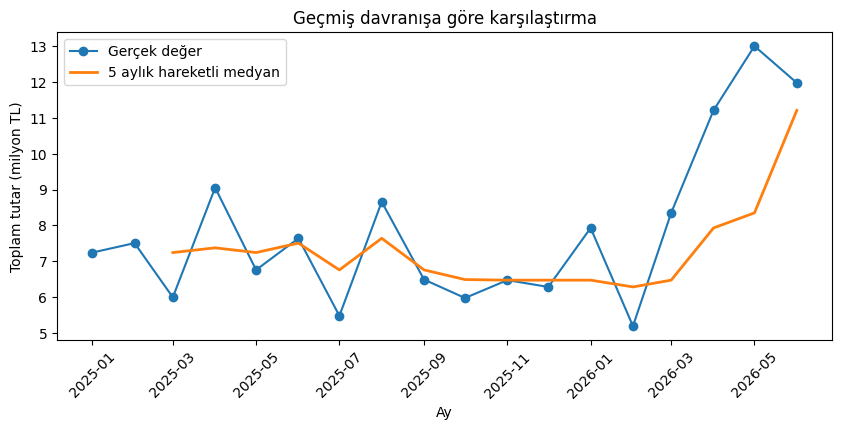

In [12]:
aylik["hareketli_medyan_5"] = (
    aylik["toplam_tutar"]
    .rolling(window=5, min_periods=3)
    .median()
)

plt.figure(figsize=(10, 4))
plt.plot(
    aylik["tarih"],
    aylik["toplam_tutar"] / 1_000_000,
    marker="o",
    label="Gerçek değer"
)
plt.plot(
    aylik["tarih"],
    aylik["hareketli_medyan_5"] / 1_000_000,
    linewidth=2,
    label="5 aylık hareketli medyan"
)
plt.xlabel("Ay")
plt.ylabel("Toplam tutar (milyon TL)")
plt.title("Geçmiş davranışa göre karşılaştırma")
plt.xticks(rotation=45)
plt.legend()
plt.show()

## 4.2 Robust sapma: “Bu ay geçmişe göre ne kadar garip?”

Sadece çizgi grafiğine bakmak faydalıdır ama insan gözü her zaman tutarlı değildir.

Basit bir risk göstergesi üretmek için mevcut değer ile hareketli medyan arasındaki farkı ölçebiliriz.

Daha sonra bu farkı, geçmişteki tipik sapma büyüklüğüne göre ölçekleyebiliriz.

Burada **MAD — Median Absolute Deviation** fikri devreye girer.

MAD, standart sapmanın daha dayanıklı kuzeni gibi düşünülebilir.

Temel fikir:

1. Medyanı bul.
2. Her değerin medyandan ne kadar uzak olduğuna bak.
3. Bu uzaklıkların medyanını al.

Uç değerler MAD'i standart sapma kadar kolay bozamaz.

In [13]:
def rolling_mad(series, window=5):
    return series.rolling(window, min_periods=3).apply(
        lambda x: np.median(np.abs(x - np.median(x))),
        raw=True
    )

aylik["mad_5"] = rolling_mad(aylik["toplam_tutar"], window=5)

# Sıfıra bölmeyi önlemek için çok küçük değerlere NaN veriyoruz.
mad_safe = aylik["mad_5"].replace(0, np.nan)

aylik["robust_sapma"] = (
    (aylik["toplam_tutar"] - aylik["hareketli_medyan_5"]).abs()
    / mad_safe
)

aylik[["tarih", "toplam_tutar", "hareketli_medyan_5", "robust_sapma"]].tail(10)

,tarih,toplam_tutar,hareketli_medyan_5,robust_sapma
8,2025-09-01,6.489640e+06,6.758665e+06,0.304720
9,2025-10-01,5.975057e+06,6.489640e+06,0.508158
10,2025-11-01,6.473222e+06,6.473222e+06,0.000000
11,2025-12-01,6.283685e+06,6.473222e+06,1.000000
12,2026-01-01,7.929879e+06,6.473222e+06,7.685337
13,2026-02-01,5.191076e+06,6.283685e+06,3.540213
14,2026-03-01,8.351560e+06,6.473222e+06,1.464997
15,2026-04-01,1.121176e+07,7.929879e+06,1.993616
16,2026-05-01,1.300791e+07,8.351560e+06,1.627983
17,2026-06-01,1.198129e+07,1.121176e+07,0.428434


In [14]:
# Eğitim amaçlı basit eşik:
aylik["zaman_anomali_flag"] = aylik["robust_sapma"] > 3

aylik.loc[
    aylik["zaman_anomali_flag"],
    ["tarih", "toplam_tutar", "hareketli_medyan_5", "robust_sapma"]
]

,tarih,toplam_tutar,hareketli_medyan_5,robust_sapma
2,2025-03-01,5994471.22,7.243317e+06,4.731880
12,2026-01-01,7929879.06,6.473222e+06,7.685337
13,2026-02-01,5191076.48,6.283685e+06,3.540213


### Burada dikkat edilmesi gereken şey

Zaman serisinde bir sıçrama gördüğünüzde hemen “sorun var” demeyin.

Önce alternatif açıklamaları düşünün:

- Mevsimsellik olabilir.
- Yıl sonu bütçe kapanışı olabilir.
- Yeni bir destek çağrısı başlamış olabilir.
- Kur değişimi parasal toplamı yükseltmiş olabilir.
- Büyük bir toplu ödeme planlı olarak gerçekleşmiş olabilir.
- Veri aktarım sistemi değişmiş olabilir.

Yani zaman serisi analizi bize **“ne zaman?”** sorusunu güçlü biçimde cevaplar.

Ama **“neden?”** sorusu için tekrar sürece, belgeye ve bağlama dönmemiz gerekir.

# 5. Üç tekniği birlikte düşünmek

Şimdi üç ayrı araç öğrendik:

### Örnekleme
**Hangi kayıtlara bakmalıyım?**

### Mahalanobis uzaklığı
**Hangi kayıtlar değişkenlerin birlikte davranışına göre sıra dışı?**

### Zaman serisi
**Davranış hangi dönemde değişti?**

Bunlar birbirinin alternatifi değildir.

Gerçek bir denetim akışı şöyle olabilir:

> Önce zaman serisiyle olağandışı dönemi bul.  
> O dönemde Mahalanobis ile sıra dışı işlemleri sırala.  
> Sonra parasal büyüklüğü ve birimleri dikkate alan örnekleme ile inceleme listesini oluştur.

Bu artık tek bir istatistik testi değil, **analitik denetim tasarımıdır**.

In [15]:
# Örnek bir birleşik inceleme listesi:
# 1) Mahalanobis açısından en sıra dışı 30 kayıt
adaylar = df.nlargest(30, "mahalanobis").copy()

# 2) Bunlardan parasal büyüklüğe ağırlık vererek 10 kayıt seç
inceleme_listesi = adaylar.sample(
    n=10,
    weights="tutar",
    random_state=42
)

inceleme_listesi[
    ["islem_id", "tarih", "birim", "tedarikci",
     "tutar", "onay_suresi_gun", "mahalanobis"]
].sort_values("mahalanobis", ascending=False)

,islem_id,tarih,birim,tedarikci,tutar,onay_suresi_gun,mahalanobis
513,TRX-00725,2025-06-22,Güney,Tedarikçi-20,1.007570e+06,11.600000,11.550773
669,TRX-00672,2025-08-19,Kuzey,Tedarikçi-13,9.303130e+05,15.600000,10.588675
679,TRX-00139,2025-08-22,Güney,Tedarikçi-29,7.874021e+05,0.752569,9.172866
491,TRX-00446,2025-06-14,Doğu,Tedarikçi-13,5.208275e+05,26.100000,5.901552
1431,TRX-00444,2026-06-01,Merkez,Tedarikçi-18,4.363099e+05,16.700000,4.438465
1444,TRX-01177,2026-06-05,Merkez,Tedarikçi-05,3.946794e+05,8.100000,4.138829
765,TRX-00366,2025-09-25,Güney,Tedarikçi-10,3.915417e+05,8.700000,4.065254
222,TRX-01284,2025-03-16,Kuzey,Tedarikçi-30,3.343382e+05,26.500000,3.830981
430,TRX-00677,2025-05-25,Güney,Tedarikçi-36,2.919271e+05,26.000000,3.334298
1130,TRX-01065,2026-02-05,Güney,Tedarikçi-31,2.333995e+05,29.300000,3.269529


# 6. Sınıf içi vaka

Kendinizi iç denetçi olarak düşünün.

Yukarıdaki veri setinde yalnızca **10 işlemi ayrıntılı inceleme** hakkınız var.

Göreviniz:

1. Hangi örnekleme mantığını kullanacağınıza karar verin.
2. Mahalanobis sonuçlarını inceleyin.
3. Zaman grafiğinde olağandışı dönem olup olmadığına bakın.
4. Son 10 işlemlik inceleme listenizi oluşturun.
5. Her kayıt için **“neden seçtim?”** açıklaması yazın.

Önemli kural:

> “Model seçti” geçerli bir denetim gerekçesi değildir.

İyi gerekçe şöyle görünür:

> “İşlem tutarı benzer kayıtlara göre yüksek, onay süresi ise alışılmadık ölçüde kısa.  
> Bu kombinasyon çok değişkenli aykırılık testinde üst sırada yer aldığı için işlem belgeleri incelenecektir.”

Analitik sonuç ancak denetim diline çevrildiğinde işe yarar.

# 7. Bu notebook'tan akılda kalması gerekenler

Bu bölümün amacı formülleri ezberletmek değildir.

Üç fikir yeterlidir:

**Bir:** Örnek seçimi nötr değildir. Seçim yöntemi, denetim sorusunu yansıtır.

**İki:** Bir kayıt tek tek değişkenlerde normal görünürken değişkenlerin birleşiminde olağandışı olabilir.

**Üç:** “Normal” kavramı zaman içinde değişebilir. Bir işlemi yalnızca diğer işlemlerle değil, kendi geçmişiyle de karşılaştırmak gerekir.

Bir sonraki notebook'ta artık ilişkiler ve nedensellik iddiasına yaklaşacağız:

- korelasyonun sınırları,
- Granger yaklaşımı,
- ilişki / network analizi,
- entegre denetim vakası.

Orada temel soru değişecek:

> **“Bu değişkenler ve aktörler birbirleriyle nasıl hareket ediyor?”**